# Aprendizaje no supervisado y complementos: Esperanza de Vida (OMS)
**Curso:** Inteligencia Artificial 1 · Proyecto final · **Grupo E1**

*Arnold Steven Navarro · Christian Jhose Moreno Rios · Julian Andres Rodriguez Montero · Marcelo Gomez Cabra*

**Dataset:** [Life Expectancy (WHO)](https://www.kaggle.com/datasets/kumarajarshi/life-expectancy-who), Kaggle.

Contenido:
1. Carga y preparación (idéntica al notebook supervisado)
2. Complemento supervisado: red densa (MLP) y validación por país (GroupKFold)
3. Reducción de dimensionalidad con PCA y número de componentes
4. Comparación supervisada con y sin PCA (misma partición y métricas)
5. Agrupamiento de países: K-means (codo y silueta), Ward y DBSCAN
6. Interpretación de los grupos y contraste con etiquetas reales
7. Conclusiones

In [1]:
# --- Opción A: subir el archivo manualmente (Colab) ---
try:
    from google.colab import files
    print("Sube el archivo 'Life Expectancy Data.csv' descargado de Kaggle:")
    uploaded = files.upload()
    RUTA_CSV = list(uploaded.keys())[0]
except ImportError:
    RUTA_CSV = "data/Life Expectancy Data.csv"   # entorno local

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, warnings
warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split, KFold, GroupKFold, GridSearchCV, cross_val_score, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, silhouette_score, adjusted_rand_score
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 100
RANDOM_STATE, TEST_SIZE = 42, 0.20

## 1. Carga y preparación
Misma preparación que el notebook supervisado: se quitan las filas sin etiqueta, `Country` queda fuera, `Status` pasa a 0/1 y la partición 80/20 usa la misma semilla. Así las comparaciones son justas.

In [3]:
df = pd.read_csv(RUTA_CSV)
df.columns = df.columns.str.strip().str.replace(r"\s+", " ", regex=True)
TARGET = "Life expectancy"
df = df.dropna(subset=[TARGET]).reset_index(drop=True)
df["Status_Developed"] = (df["Status"] == "Developed").astype(int)
FEATURES = [c for c in df.columns if c not in [TARGET, "Country", "Status"]]
X, y, grupos = df[FEATURES], df[TARGET], df["Country"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)

(2342, 20) (586, 20)


In [4]:
def evaluar(nombre, modelo, Xtr=None, Xte=None):
    Xtr = X_train if Xtr is None else Xtr; Xte = X_test if Xte is None else Xte
    p_tr, p_te = modelo.predict(Xtr), modelo.predict(Xte)
    return {"Modelo": nombre, "R² train": r2_score(y_train, p_tr), "R² test": r2_score(y_test, p_te),
            "MAE test (años)": mean_absolute_error(y_test, p_te), "RMSE test (años)": np.sqrt(mean_squared_error(y_test, p_te))}

## 2. Complemento supervisado
### 2.1 Red neuronal densa (MLP)
La rúbrica pide comparar modelos clásicos con una red densa. Igual que el SVR, la red necesita escalar las entradas y el target. Se usa *early stopping* para frenar el sobreajuste y se ajustan capas, regularización `alpha` y tasa de aprendizaje con validación cruzada de 5 folds sobre entrenamiento.

In [5]:
def modelo_mlp(**kw):
    pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()),
                     ("model", MLPRegressor(random_state=RANDOM_STATE, max_iter=2000, early_stopping=True, n_iter_no_change=30, **kw))])
    return TransformedTargetRegressor(regressor=pipe, transformer=StandardScaler())

mlp_base = modelo_mlp(hidden_layer_sizes=(64, 32)).fit(X_train, y_train)
grilla = {"regressor__model__hidden_layer_sizes": [(32,), (64, 32), (128, 64), (128, 64, 32)],
          "regressor__model__alpha": [1e-4, 1e-3, 1e-2],
          "regressor__model__learning_rate_init": [1e-3, 3e-3]}
gs_mlp = GridSearchCV(modelo_mlp(), grilla, cv=kf, scoring="r2", n_jobs=-1).fit(X_train, y_train)
print("Mejores hiperparámetros:", gs_mlp.best_params_, "| R² CV =", round(gs_mlp.best_score_, 3))
pd.DataFrame([evaluar("MLP base (64,32)", mlp_base), evaluar("MLP ajustada", gs_mlp.best_estimator_)]).set_index("Modelo").round(3)

Mejores hiperparámetros: {'regressor__model__alpha': 0.01, 'regressor__model__hidden_layer_sizes': (128, 64, 32), 'regressor__model__learning_rate_init': 0.003} | R² CV = 0.937


,R² train,R² test,MAE test (años),RMSE test (años)
Modelo,,,,
"MLP base (64,32)",0.973,0.929,1.687,2.481
MLP ajustada,0.980,0.933,1.559,2.409


**Lectura:** la red ajustada (3 capas: 128-64-32, `alpha` = 0.01) llega a un R² en prueba de 0.933 y un MAE de 1.56 años: prácticamente igual al SVR ajustado (0.932) y por debajo del Random Forest (0.968, MAE 1.05). Con 2,342 filas tabulares, una red densa no tiene ventaja sobre los árboles.

### 2.2 Validación por país (GroupKFold)
Cada país aparece hasta 16 veces. Con partición aleatoria, años vecinos del mismo país caen en entrenamiento y prueba. `GroupKFold` deja países completos fuera en cada fold y mide qué tan bien se predice un país nunca visto.

In [6]:
def modelo_rf(k=None):
    pasos = [("imputer", SimpleImputer(strategy="median"))]
    if k: pasos += [("scaler", StandardScaler()), ("pca", PCA(n_components=k, random_state=RANDOM_STATE))]
    return Pipeline(pasos + [("model", RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1))])
def modelo_svr(k=None):
    pasos = [("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
    if k: pasos += [("pca", PCA(n_components=k, random_state=RANDOM_STATE))]
    return TransformedTargetRegressor(Pipeline(pasos + [("model", SVR(C=10, epsilon=0.05, gamma="scale"))]), transformer=StandardScaler())
def modelo_red(k=None):
    pasos = [("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
    if k: pasos += [("pca", PCA(n_components=k, random_state=RANDOM_STATE))]
    red = MLPRegressor(hidden_layer_sizes=(128, 64, 32), alpha=0.01, learning_rate_init=0.003, random_state=RANDOM_STATE,
                       max_iter=2000, early_stopping=True, n_iter_no_change=30)
    return TransformedTargetRegressor(Pipeline(pasos + [("model", red)]), transformer=StandardScaler())

filas = []
for nombre, m in [("Random Forest", modelo_rf()), ("SVR", modelo_svr()), ("Red densa", modelo_red())]:
    alea = cross_validate(m, X, y, cv=kf, scoring=("r2", "neg_mean_absolute_error"))
    pais = cross_validate(m, X, y, cv=GroupKFold(n_splits=5), groups=grupos, scoring=("r2", "neg_mean_absolute_error"))
    filas.append({"Modelo": nombre, "R² K-fold aleatorio": alea["test_r2"].mean(), "MAE aleatorio": -alea["test_neg_mean_absolute_error"].mean(),
                  "R² GroupKFold (país)": pais["test_r2"].mean(), "MAE país": -pais["test_neg_mean_absolute_error"].mean()})
pd.DataFrame(filas).set_index("Modelo").round(3)

,R² K-fold aleatorio,MAE aleatorio,R² GroupKFold (país),MAE país
Modelo,,,,
Random Forest,0.963,1.147,0.903,2.109
SVR,0.938,1.508,0.852,2.454
Red densa,0.937,1.596,0.829,2.443


**Lectura:** al predecir países no vistos el R² del bosque baja de 0.963 a 0.903 y el MAE sube de 1.15 a 2.11 años. Esa es la estimación honesta para un país nuevo; el bosque sigue siendo el mejor.

## 3. Reducción de dimensionalidad con PCA
Se usan las mismas 20 variables, imputadas con la mediana y estandarizadas (PCA es sensible a la escala). El PCA se ajusta **solo con entrenamiento** para no filtrar información del conjunto de prueba.

80% de varianza -> 9 componentes
90% de varianza -> 12 componentes
95% de varianza -> 15 componentes
Criterio de Kaiser (autovalor > 1): 6 componentes


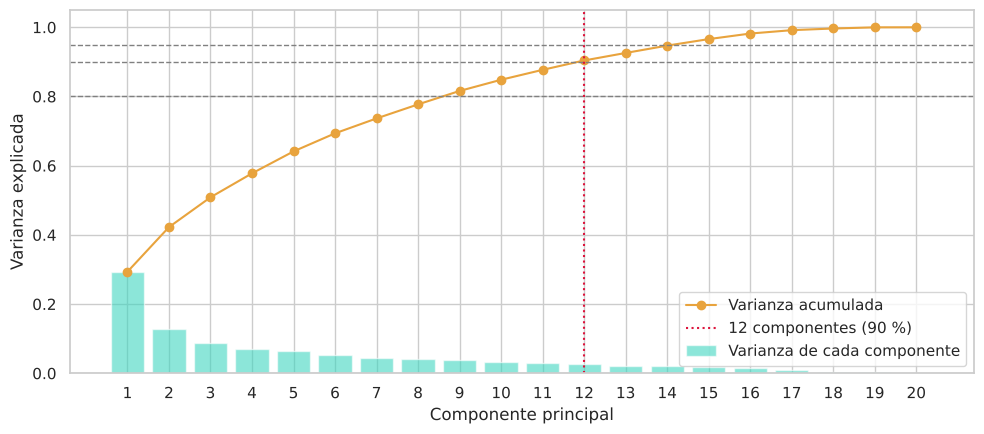

In [7]:
pre = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]).fit(X_train)
pca = PCA().fit(pre.transform(X_train))
var, acum = pca.explained_variance_ratio_, np.cumsum(pca.explained_variance_ratio_)
for u in [0.80, 0.90, 0.95]: print(f"{u:.0%} de varianza -> {np.argmax(acum >= u) + 1} componentes")
print("Criterio de Kaiser (autovalor > 1):", (pca.explained_variance_ > 1).sum(), "componentes")
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(range(1, 21), var, color="#3fd6c0", alpha=.6, label="Varianza de cada componente")
ax.plot(range(1, 21), acum, "o-", color="#e8a33d", label="Varianza acumulada")
for u in [0.8, 0.9, 0.95]: ax.axhline(u, ls="--", lw=1, color="gray")
ax.axvline(12, color="crimson", ls=":", label="12 componentes (90 %)")
ax.set_xlabel("Componente principal"); ax.set_ylabel("Varianza explicada"); ax.set_xticks(range(1, 21)); ax.legend(); plt.tight_layout(); plt.show()

In [8]:
cargas = pd.DataFrame(pca.components_[:3].T, index=FEATURES, columns=["PC1", "PC2", "PC3"]).round(2)
cargas.sort_values("PC1")

,PC1,PC2,PC3
thinness 1-19 years,-0.31,0.14,0.16
thinness 5-9 years,-0.31,0.14,0.16
under-five deaths,-0.22,0.48,0.04
Adult Mortality,-0.22,-0.16,-0.15
infant deaths,-0.21,0.48,0.05
Measles,-0.13,0.31,-0.01
HIV/AIDS,-0.13,-0.11,-0.20
Population,-0.09,0.36,0.08
Year,0.07,0.04,0.16
Hepatitis B,0.12,-0.05,0.43


**Decisión:** conservamos **12 componentes**, que explican el 90 % de la varianza con 40 % menos de dimensiones. El criterio de Kaiser sugiere 6, pero con tan pocas componentes se pierde demasiada información para predecir (ver la sección 4).

**Interpretación:** PC1 (29 % de la varianza) es un eje de desarrollo: escolaridad (0.32), ingreso (0.30) e IMC (0.28) en un extremo; delgadez (−0.31) y mortalidad adulta (−0.22) en el otro. PC2 recoge el tamaño poblacional (muertes infantiles y menores de 5 en números absolutos, población).

## 4. Comparación supervisada con y sin PCA
Misma partición 80/20, mismos modelos y mismas métricas. La referencia son las 20 variables originales (la configuración de la segunda entrega).

In [9]:
filas = []
for nombre, fabrica in [("Random Forest", modelo_rf), ("SVR", modelo_svr), ("Red densa", modelo_red)]:
    for k in [2, 5, 8, 10, 12, 15, None]:
        m = fabrica(k).fit(X_train, y_train)
        r = evaluar(nombre, m); r["Dimensiones"] = k or 20; filas.append(r)
comp = pd.DataFrame(filas)
tabla = comp.pivot(index="Dimensiones", columns="Modelo", values="R² test").round(3)
display(tabla)
display(comp[comp["Dimensiones"].isin([12, 20])].set_index(["Modelo", "Dimensiones"]).round(3))

Modelo,Random Forest,Red densa,SVR
Dimensiones,,,
2,0.708,0.748,0.740
5,0.847,0.847,0.838
8,0.867,0.899,0.880
10,0.862,0.888,0.884
12,0.867,0.887,0.890
15,0.887,0.942,0.932
20,0.967,0.933,0.932


R² train  R² test  MAE test (años)  \
Modelo        Dimensiones                                       
Random Forest 12              0.985    0.867            2.247   
              20              0.995    0.967            1.053   
SVR           12              0.951    0.890            2.028   
              20              0.976    0.932            1.481   
Red densa     12              0.950    0.887            2.150   
              20              0.980    0.933            1.559   

                           RMSE test (años)  
Modelo        Dimensiones                    
Random Forest 12                      3.389  
              20                      1.677  
SVR           12                      3.080  
              20                      2.421  
Red densa     12                      3.131  
              20                      2.409

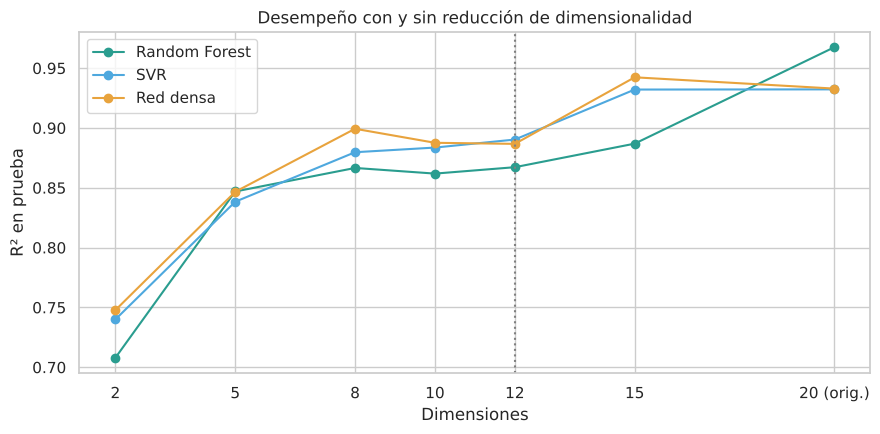

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for nombre, c in [("Random Forest", "#2a9d8f"), ("SVR", "#4ea8de"), ("Red densa", "#e8a33d")]:
    d = comp[comp.Modelo == nombre].sort_values("Dimensiones")
    ax.plot(d["Dimensiones"], d["R² test"], "o-", color=c, label=nombre)
ax.axvline(12, color="gray", ls=":"); ax.set_xticks([2, 5, 8, 10, 12, 15, 20]); ax.set_xticklabels(["2", "5", "8", "10", "12", "15", "20 (orig.)"])
ax.set_xlabel("Dimensiones"); ax.set_ylabel("R² en prueba"); ax.set_title("Desempeño con y sin reducción de dimensionalidad"); ax.legend(); plt.tight_layout(); plt.show()

**Lectura crítica:**
- Con 12 componentes el Random Forest cae de 0.967 a 0.867 (MAE de 1.05 a 2.25 años). Cada componente mezcla las 20 variables, así que el árbol pierde cortes limpios como "VIH/sida > 1", la variable que explica el 60 % de su importancia.
- SVR y la red trabajan ya en un espacio escalado y combinado: pierden menos y con 15 componentes recuperan (SVR 0.932) o incluso mejoran ligeramente (red 0.942 frente a 0.933).
- Con solo 20 variables no hay maldición de la dimensionalidad: para el mejor modelo, la referencia original sigue siendo mejor.

## 5. Agrupamiento de países
**Diseño:** cada país tiene 16 filas casi iguales, así que agrupamos **países** (promedio 2000–2015), no filas. Aplicamos logaritmo a las variables muy asimétricas (lo sugerido en el EDA), imputamos con la mediana y estandarizamos. No se usan ni la etiqueta ni `Status`: sirven después para contrastar.

In [11]:
VARS = [c for c in FEATURES if c not in ["Year", "Status_Developed"]]
g = df.groupby("Country")
paises = g[VARS].mean(); paises[TARGET] = g[TARGET].mean(); paises["Status"] = g["Status"].agg(lambda s: s.mode()[0])
Xc = paises[VARS].copy()
for c in ["GDP", "Population", "Measles", "infant deaths", "under-five deaths", "percentage expenditure", "HIV/AIDS"]:
    Xc[c] = np.log1p(Xc[c])
Z = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(Xc))
print("Países:", Z.shape[0], "| variables:", Z.shape[1])

Países: 183 | variables: 18


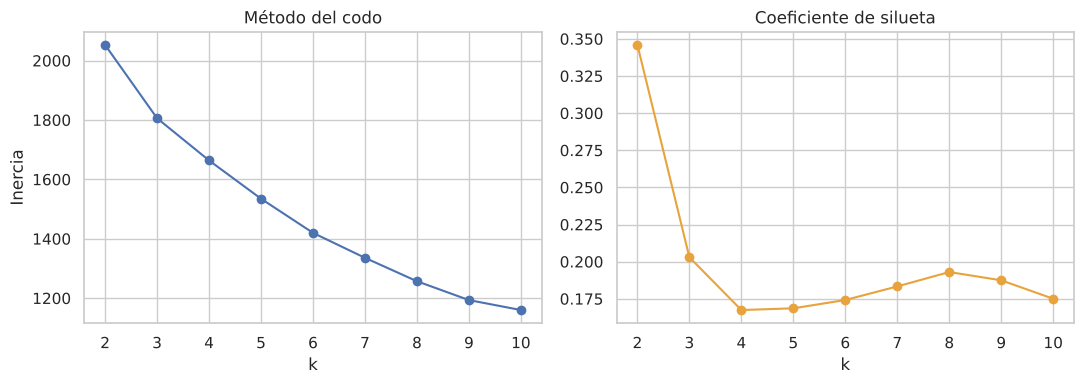

k,2,3,4,5,6,7,8,9,10
inercia,2053.000,1806.000,1664.000,1535.000,1420.000,1336.000,1257.000,1193.000,1160.000
silueta,0.346,0.203,0.167,0.169,0.174,0.183,0.193,0.187,0.175


In [12]:
ks = range(2, 11); inercia, silueta = [], []
for k in ks:
    km = KMeans(k, n_init=20, random_state=RANDOM_STATE).fit(Z)
    inercia.append(km.inertia_); silueta.append(silhouette_score(Z, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inercia, "o-"); ax[0].set_title("Método del codo"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inercia")
ax[1].plot(ks, silueta, "o-", color="#e8a33d"); ax[1].set_title("Coeficiente de silueta"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()
pd.DataFrame({"k": ks, "inercia": np.round(inercia, 0), "silueta": np.round(silueta, 3)}).set_index("k").T

**Selección de k:** el codo no es nítido; la silueta es máxima con **k = 2** (0.35), que separa países con alta mortalidad del resto. Usamos **k = 3** (silueta 0.20) para interpretar, porque divide el grupo grande en desarrollo medio y alto sin degradar mucho la cohesión.

In [13]:
def kmeans_ordenado(k):
    lab = KMeans(k, n_init=20, random_state=RANDOM_STATE).fit_predict(Z)
    orden = pd.Series(paises[TARGET].values).groupby(lab).mean().sort_values().index
    return np.array([list(orden).index(l) + 1 for l in lab])
paises["k2"], paises["k3"] = kmeans_ordenado(2), kmeans_ordenado(3)
ward3 = AgglomerativeClustering(3, linkage="ward").fit_predict(Z); ward2 = AgglomerativeClustering(2, linkage="ward").fit_predict(Z)
print("Acuerdo K-means vs Ward (ARI): k=2 ->", round(adjusted_rand_score(paises.k2, ward2), 2), "| k=3 ->", round(adjusted_rand_score(paises.k3, ward3), 2))

Acuerdo K-means vs Ward (ARI): k=2 -> 0.75 | k=3 -> 0.55


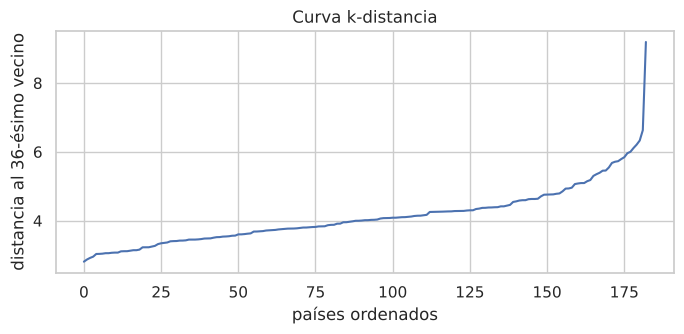

eps=2.5: grupos=0, ruido=183
eps=3.0: grupos=1, ruido=122
eps=3.5: grupos=2, ruido=32
eps=4.0: grupos=1, ruido=12


In [14]:
# DBSCAN: eps orientado con la curva de distancia al k-ésimo vecino (min_samples = 2 × dimensiones)
ms = 2 * Z.shape[1]
d, _ = NearestNeighbors(n_neighbors=ms).fit(Z).kneighbors(Z)
plt.figure(figsize=(7, 3.5)); plt.plot(np.sort(d[:, -1])); plt.ylabel(f"distancia al {ms}-ésimo vecino"); plt.xlabel("países ordenados"); plt.title("Curva k-distancia"); plt.tight_layout(); plt.show()
for eps in [2.5, 3.0, 3.5, 4.0]:
    l = DBSCAN(eps=eps, min_samples=ms).fit_predict(Z)
    print(f"eps={eps}: grupos={len(set(l)) - (-1 in l)}, ruido={(l == -1).sum()}")

**DBSCAN:** la curva k-distancia no muestra un codo claro y, según `eps`, todo queda como ruido o en un solo grupo (con eps = 3.5: 2 grupos y 32 países de ruido). Los países no forman grupos densos separados sino un continuo de desarrollo, por eso K-means es más útil aquí.

## 6. Interpretación y contraste con etiquetas reales

Varianza PC1, PC2: [0.478 0.103]


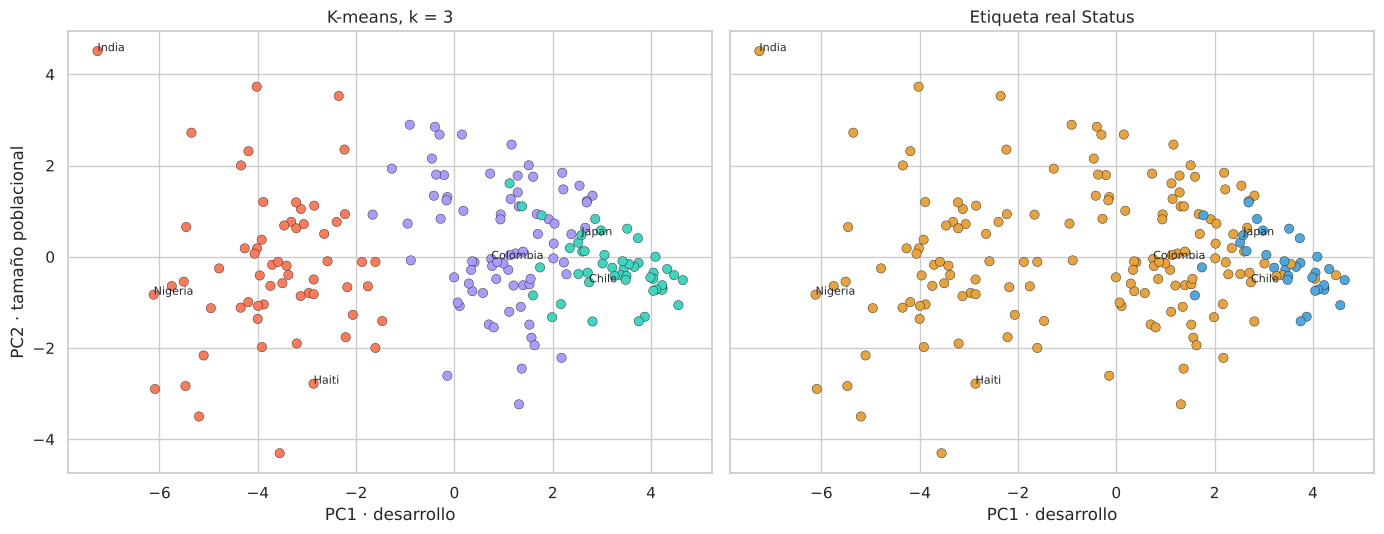

In [15]:
pca2 = PCA(2).fit(Z); P = pca2.transform(Z)
print("Varianza PC1, PC2:", pca2.explained_variance_ratio_.round(3))
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
ax[0].scatter(P[:, 0], P[:, 1], c=paises.k3.map({1: "#ff7a59", 2: "#a99bff", 3: "#3fd6c0"}), s=45, edgecolor="k", lw=.3); ax[0].set_title("K-means, k = 3")
ax[1].scatter(P[:, 0], P[:, 1], c=paises.Status.map({"Developing": "#e8a33d", "Developed": "#4ea8de"}), s=45, edgecolor="k", lw=.3); ax[1].set_title("Etiqueta real Status")
for a in ax:
    a.set_xlabel("PC1 · desarrollo")
    for n in ["Colombia", "Japan", "Nigeria", "Chile", "Haiti", "India"]:
        i = paises.index.get_loc(n); a.annotate(n, P[i], fontsize=8)
ax[0].set_ylabel("PC2 · tamaño poblacional"); plt.tight_layout(); plt.show()

In [16]:
perfil = paises.groupby("k3").agg(paises=(TARGET, "size"), esperanza_vida=(TARGET, "mean"), VIH=("HIV/AIDS", "mean"),
                                   escolaridad=("Schooling", "mean"), difteria=("Diphtheria", "mean"), PIB_mediano=("GDP", "median"))
perfil.round(2)

,paises,esperanza_vida,VIH,escolaridad,difteria,PIB_mediano
k3,,,,,,
1,61,58.77,4.58,8.79,65.58,556.44
2,75,72.04,0.47,12.35,89.02,2947.61
3,47,78.30,0.11,15.58,92.82,13898.89


In [17]:
rangos = pd.cut(paises[TARGET], [0, 60, 70, 100], labels=["< 60", "60-70", "> 70"])
display(pd.crosstab(paises.k3, rangos, margins=True))
display(pd.crosstab(paises.k3, paises.Status, margins=True))
print("ARI k=3 vs Status:", round(adjusted_rand_score(paises.k3, paises.Status), 2))

Life expectancy,< 60,60-70,> 70,All
k3,,,,
1,35,23,3,61
2,2,17,56,75
3,0,2,45,47
All,37,42,104,183


Status,Developed,Developing,All
k3,,,
1,0,61,61
2,1,74,75
3,31,16,47
All,32,151,183


ARI k=3 vs Status: 0.23


**Lectura:**
- Los tres grupos tienen esperanza de vida media de 58.8, 72.0 y 78.3 años, y cambian juntos el VIH/sida, la escolaridad, la vacunación y el PIB.
- Sin ver la etiqueta, 35 de los 37 países con menos de 60 años quedan en el grupo 1 y 45 de los 47 del grupo 3 superan los 70.
- Frente a `Status`: 31 de 32 países desarrollados caen en el grupo 3, pero junto a 16 "en desarrollo" como Chile. `Status` es una etiqueta gruesa (ARI = 0.23); los grupos capturan mejor el nivel real de salud y desarrollo.

**Limitaciones:** promediar 16 años oculta la evolución de cada país; la silueta baja (0.20 con k = 3) indica grupos que se tocan; los resultados dependen de la transformación logarítmica y del escalado.

## 7. Conclusiones
- **EDA:** la limpieza (ceros falsos, saltos de mortalidad, nulos) definió el pipeline.
- **Supervisado:** Random Forest es el mejor (R² 0.968, MAE 1.05 años). La red densa iguala al SVR, no lo supera. Validando por país, el bosque baja a R² 0.903.
- **Reducción de dimensionalidad:** 12 componentes guardan el 90 % de la varianza, pero empeoran la predicción del bosque; con 20 variables no compensa reducir.
- **Agrupamiento:** sin etiqueta aparecen perfiles de desarrollo que coinciden con la esperanza de vida real.
- **Mejoras:** imputación por país, transformación logarítmica en el modelo supervisado, boosting y validación por país desde el inicio.